<a href="https://colab.research.google.com/github/thaslima921/Unit_Test/blob/main/next_word_prediction_using_lstm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Detail
In this project we predict the next word in a given text input using an LSTM model. The application leverages TensorFlow and a pre-trained LSTM model to generate word predictions.

# Data Set
 We use nltk dataset in this project, nltk.download('gutenberg')
 that is built in nltk library

 # Model
 We Use LSTM (Long short term memory)

 # Why we Use This
LSTMs introduce memory cells that can maintain information over long periods. These cells help the network remember and utilize information from earlier time steps.

# LSTM Gates

LSTMs use three main gates to regulate the flow of information:
Forget Gate: Determines what portion of the previous cell state should be discarded.
Input Gate: Decides what new information should be added to the cell state.
Output Gate: Controls the output based on the cell state and decides what part of the cell state should be outputted.

In [2]:
import nltk

nltk.download('gutenberg')
nltk.download('punkt')
nltk.download('punkt_tab')

print("NLTK resources downloaded successfully!")

[nltk_data] Downloading package gutenberg to /root/nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


NLTK resources downloaded successfully!


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [3]:
import numpy as np
import nltk
nltk.download('gutenberg')
from nltk.corpus import gutenberg
data = gutenberg.raw('shakespeare-hamlet.txt')

[nltk_data] Downloading package gutenberg to /root/nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!


# Library Thats We use in this project

In [4]:
# Tensorflow librarry
import tensorflow as tf

# The main reason for using a tokenizer in natural language processing (NLP) is to convert text into a format that can be understood and processed by machine learning models.
from tensorflow.keras.preprocessing.text import Tokenizer

# LSTM FOR MODEL
# Dropout for model overfitting
from tensorflow.keras.layers import Dense,LSTM,Dropout,Embedding
from tensorflow.keras.models import Sequential

# pad_sequences use for word equal length
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [5]:
# We can save this data into file
with open('hamlet.txt','w') as f:
    f.write(data)

In [6]:
with open('hamlet.txt','r') as f:
    text = f.read().lower()

In [7]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])
total_words = len(tokenizer.word_index) + 1

# Tokenizer Text
1. In Next Line We convert our text into number
1. S for that we use tokenizer.texts_to_sequences
1. thats convert our data like that
1. e.g
this : 1


In [8]:
input_sequences = []
for line in text.split('\n'):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1,len(token_list)):
        n_grams_text = token_list[:i+1]
        input_sequences.append(n_grams_text)

In [9]:
max_length = max([len(x) for x in input_sequences])
print(max_length)
input_sequences = np.array(pad_sequences(input_sequences,maxlen=max_length,padding='pre'))
input_sequences[:5]

14


array([[   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    1,  687],
       [   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           1,  687,    4],
       [   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    1,
         687,    4,   45],
       [   0,    0,    0,    0,    0,    0,    0,    0,    0,    1,  687,
           4,   45,   41],
       [   0,    0,    0,    0,    0,    0,    0,    0,    1,  687,    4,
          45,   41, 1886]], dtype=int32)

In [10]:
# For Train And Test
from sklearn.model_selection import train_test_split

X = input_sequences[:,:-1]
y = input_sequences[:,-1]
y = tf.keras.utils.to_categorical(y,num_classes=total_words)
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

# Build model Sequential

In [11]:
model = Sequential()
model.add(Embedding(total_words,100,input_length=max_length-1))
model.add(LSTM(100,return_sequences=True))
model.add(Dropout(0.2))
model.add(LSTM(100))
model.add(Dense(total_words,activation='softmax'))
model.build(input_shape=(None,max_length-1))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 13, 100)        │       481,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 13, 100)        │        80,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 100)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100)            │        80,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4818)           │       486,618 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,129,218 (4.31 MB)

 Trainable params: 1,129,218 (4.31 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# compile model
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [13]:
history = model.fit(X_train,y_train,epochs=75,validation_data=(X_test,y_test),verbose=1)

Epoch 1/75
644/644 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - accuracy: 0.0334 - loss: 6.9041 - val_accuracy: 0.0321 - val_loss: 6.7146
Epoch 2/75
644/644 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.0373 - loss: 6.4257 - val_accuracy: 0.0346 - val_loss: 6.7736
Epoch 3/75
644/644 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.0427 - loss: 6.2753 - val_accuracy: 0.0416 - val_loss: 6.8487
Epoch 4/75
644/644 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.0497 - loss: 6.1282 - val_accuracy: 0.0427 - val_loss: 6.9074
Epoch 5/75
644/644 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.0510 - loss: 5.9939 - val_accuracy: 0.0453 - val_loss: 6.9737
Epoch 6/75
644/644 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.0533 - loss: 5.8545 - val_accuracy: 0.0443 - val_loss: 7.0401
Epoch 7/75
644/644 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.0575 - loss: 5.7241 - val_accuracy: 0.0443 - val_loss: 7.1323
Epoch 8/75
644/644 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.0634 - loss: 5.6015 - val_acc

In [14]:
def prediction_model(model,tokenizer,input,max_seq_len):
  tokenizer = tokenizer
  input = input.lower()
  token_list = tokenizer.texts_to_sequences([input])[0]
  token_list = pad_sequences([token_list],maxlen=max_seq_len-1,padding='pre')
  predicted = model.predict(token_list,verbose=0)
  predicted = np.argmax(predicted,axis=1)
  output_word = ''
  for word,index in tokenizer.word_index.items():
    if index == predicted:
      output_word = word
      break
  return output_word


In [15]:

input_text = 'if your age is 70 its mean you are'
max_seq =model.input_shape[1] + 1
next_word = prediction_model(model,tokenizer,input_text,max_length)
print(f'Next Word Prediction: {next_word}')

Next Word Prediction: free


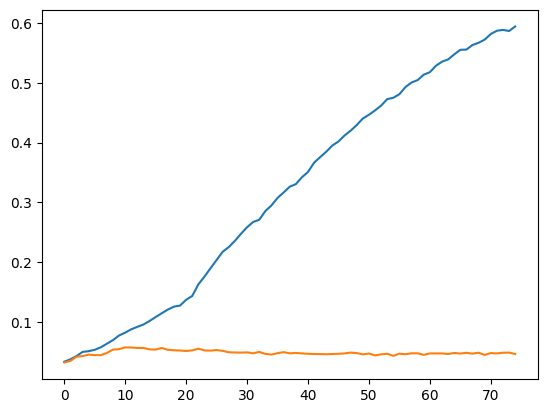

In [16]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

Text(0.5, 1.0, 'Loss of Model')

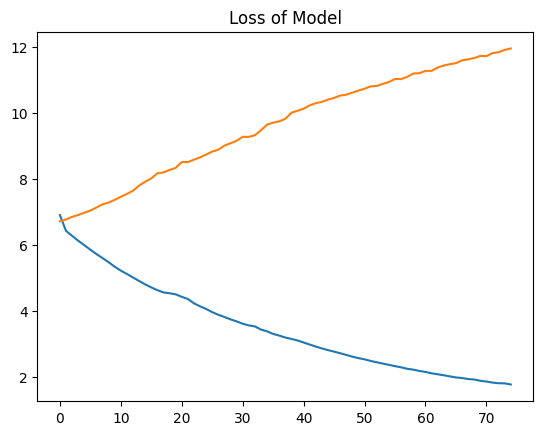

In [17]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Loss of Model')

In [19]:
import re
import nltk
from nltk.corpus import gutenberg

nltk.download('gutenberg', quiet=True)

sentences = []

for file_id in gutenberg.fileids():
    text = gutenberg.raw(file_id).lower()

    # Split the raw text using punctuation
    parts = re.split(r'(?<=[.!?])\s+', text)

    for sentence in parts:
        sentence = re.sub(r"[^a-zA-Z'\s]", " ", sentence)
        sentence = re.sub(r"\s+", " ", sentence).strip()

        if len(sentence.split()) >= 3:
            sentences.append(sentence)

sentences = list(dict.fromkeys(sentences))
sentences = sentences[:10000]

print("Sentences loaded:", len(sentences))
print("Sample:", sentences[:5])

Sentences loaded: 10000
Sample: ['emma by jane austen volume i chapter i emma woodhouse handsome clever and rich with a comfortable home and happy disposition seemed to unite some of the best blessings of existence and had lived nearly twenty one years in the world with very little to distress or vex her', "she was the youngest of the two daughters of a most affectionate indulgent father and had in consequence of her sister's marriage been mistress of his house from a very early period", 'her mother had died too long ago for her to have more than an indistinct remembrance of her caresses and her place had been supplied by an excellent woman as governess who had fallen little short of a mother in affection', 'sixteen years had miss taylor been in mr', "woodhouse's family less as a governess than a friend very fond of both daughters but particularly of emma"]


In [20]:

from tensorflow.keras.preprocessing.text import Tokenizer

MAX_VOCAB = 8000
MAX_CONTEXT = 5

tokenizer = Tokenizer(
    num_words=MAX_VOCAB,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(sentences)

VOCAB_SIZE = min(MAX_VOCAB, len(tokenizer.word_index) + 1)

tokenized_sentences = tokenizer.texts_to_sequences(sentences)

print("Total unique words:", len(tokenizer.word_index))
print("Vocabulary size used:", VOCAB_SIZE)

print("\nOriginal sentence:")
print(sentences[0])

print("\nTokenized sentence:")
print(tokenized_sentences[0])


Total unique words: 8999
Vocabulary size used: 8000

Original sentence:
emma by jane austen volume i chapter i emma woodhouse handsome clever and rich with a comfortable home and happy disposition seemed to unite some of the best blessings of existence and had lived nearly twenty one years in the world with very little to distress or vex her

Tokenized sentence:
[48, 38, 121, 4300, 2502, 7, 374, 7, 48, 126, 499, 726, 4, 967, 23, 6, 575, 155, 4, 177, 780, 145, 3, 3585, 92, 5, 2, 242, 1931, 5, 1707, 4, 15, 600, 837, 556, 61, 273, 11, 2, 267, 23, 26, 72, 3, 742, 51, 3586, 9]


In [21]:

from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
import numpy as np

MAX_CONTEXT = 5

examples = []

for tokens in tokenized_sentences:
    if len(tokens) < 2:
        continue

    for i in range(1, len(tokens)):
        context = tokens[max(0, i - MAX_CONTEXT):i]
        target = tokens[i]
        examples.append((context, target))

# Convert variable-length inputs to fixed-length inputs
X = pad_sequences(
    [item[0] for item in examples],
    maxlen=MAX_CONTEXT,
    padding="pre",
    truncating="pre"
)

y = np.array([item[1] for item in examples], dtype=np.int32)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Total input-target examples:", len(X))
print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

print("\nExample input IDs:", X_train[0])
print("Example target ID:", y_train[0])
print("Target word:", tokenizer.index_word.get(y_train[0], "<unknown>"))


Total input-target examples: 231805
Input shape: (231805, 5)
Target shape: (231805,)
Training examples: 185444
Testing examples: 46361

Example input IDs: [  0 461   7 400 102]
Example target ID: 24
Target word: his


In [24]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64, use_cudnn=False),
    Dropout(0.2),
    Dense(VOCAB_SIZE, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=[
        "sparse_categorical_accuracy",
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5, name="top5_accuracy"
        )
    ]
)

model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [25]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=1,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.10,
    epochs=4,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM training completed!")


Epoch 1/4
1304/1304 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - loss: 6.3945 - sparse_categorical_accuracy: 0.0515 - top5_accuracy: 0.1701 - val_loss: 6.0636 - val_sparse_categorical_accuracy: 0.0785 - val_top5_accuracy: 0.2067
Epoch 2/4
1304/1304 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 5.8689 - sparse_categorical_accuracy: 0.0883 - top5_accuracy: 0.2300 - val_loss: 5.8253 - val_sparse_categorical_accuracy: 0.1000 - val_top5_accuracy: 0.2500
Epoch 3/4
1304/1304 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 5.6409 - sparse_categorical_accuracy: 0.1068 - top5_accuracy: 0.2593 - val_loss: 5.6856 - val_sparse_categorical_accuracy: 0.1147 - val_top5_accuracy: 0.2723
Epoch 4/4
1304/1304 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 5.4698 - sparse_categorical_accuracy: 0.1203 - top5_accuracy: 0.2785 - val_loss: 5.5850 - val_sparse_categorical_accuracy: 0.1247 - val_top5_accuracy: 0.2877
LSTM training completed!


In [26]:

import numpy as np

# Evaluate on the held-out test set
test_results = model.evaluate(X_test, y_test, verbose=0)

print("Test loss:", round(test_results[0], 4))
print("Test Top-1 accuracy:", f"{test_results[1] * 100:.2f}%")
print("Test Top-5 accuracy:", f"{test_results[2] * 100:.2f}%")


Test loss: 5.5548
Test Top-1 accuracy: 12.19%
Test Top-5 accuracy: 28.37%


In [28]:

def predict_next_words(phrase, k=5):
    token_ids = tokenizer.texts_to_sequences([phrase.lower()])[0]

    if not token_ids:
        print("No recognized words in the phrase.")
        return

    padded = pad_sequences(
        [token_ids],
        maxlen=MAX_CONTEXT,
        padding="pre",
        truncating="pre"
    )

    probabilities = model.predict(padded, verbose=0)[0].copy()
    probabilities[0] = 0

    valid_ids = [
        idx for idx in range(1, VOCAB_SIZE)
        if idx in tokenizer.index_word
    ]

    best_ids = sorted(
        valid_ids,
        key=lambda idx: probabilities[idx],
        reverse=True
    )[:k]

    print(f"\nInput phrase: {phrase}")
    print("Top next-word predictions:")

    for rank, idx in enumerate(best_ids, start=1):
        word = tokenizer.index_word[idx]
        score = probabilities[idx] * 100
        print(f"{rank}. {word} — {score:.2f}%")


In [29]:
test_phrases = [
    "to be or not",
    "i love thee",
    "the king of",
    "what is the",
    "it is a"
]

for phrase in test_phrases:
    predict_next_words(phrase, k=5)


Input phrase: to be or not
Top next-word predictions:
1. the — 4.15%
2. a — 3.13%
3. i — 2.46%
4. she — 1.64%
5. it — 1.36%

Input phrase: i love thee
Top next-word predictions:
1. to — 10.74%
2. and — 9.21%
3. in — 4.85%
4. of — 3.60%
5. as — 3.29%

Input phrase: the king of
Top next-word predictions:
1. the — 17.86%
2. her — 6.29%
3. a — 4.67%
4. his — 3.59%
5. all — 1.89%

Input phrase: what is the
Top next-word predictions:
1. very — 1.58%
2. same — 1.53%
3. other — 1.09%
4. world — 1.07%
5. little — 0.89%

Input phrase: it is a
Top next-word predictions:
1. very — 2.86%
2. great — 2.45%
3. little — 2.37%
4. other — 1.21%
5. thing — 1.18%


In [30]:

import numpy as np

test_results = model.evaluate(X_test, y_test, verbose=0)

print("Test loss:", round(test_results[0], 4))
print("Test Top-1 accuracy:", f"{test_results[1] * 100:.2f}%")
print("Test Top-5 accuracy:", f"{test_results[2] * 100:.2f}%")


Test loss: 5.5548
Test Top-1 accuracy: 12.19%
Test Top-5 accuracy: 28.37%


In [31]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop_more = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_more = model.fit(
    X_train,
    y_train,
    validation_split=0.10,
    initial_epoch=4,
    epochs=7,
    batch_size=128,
    callbacks=[early_stop_more],
    verbose=1
)

print("Additional training completed!")


Epoch 5/7
1304/1304 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 5.3328 - sparse_categorical_accuracy: 0.1302 - top5_accuracy: 0.2935 - val_loss: 5.5236 - val_sparse_categorical_accuracy: 0.1327 - val_top5_accuracy: 0.2970
Epoch 6/7
1304/1304 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 5.2269 - sparse_categorical_accuracy: 0.1365 - top5_accuracy: 0.3055 - val_loss: 5.4851 - val_sparse_categorical_accuracy: 0.1375 - val_top5_accuracy: 0.3032
Epoch 7/7
1304/1304 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 5.1364 - sparse_categorical_accuracy: 0.1428 - top5_accuracy: 0.3148 - val_loss: 5.4669 - val_sparse_categorical_accuracy: 0.1393 - val_top5_accuracy: 0.3085
Additional training completed!


In [32]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop_more = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history_more = model.fit(
    X_train,
    y_train,
    validation_split=0.10,
    initial_epoch=7,
    epochs=18,
    batch_size=128,
    callbacks=[early_stop_more],
    verbose=1
)

print("Training completed!")


Epoch 8/18
1304/1304 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 5.0550 - sparse_categorical_accuracy: 0.1467 - top5_accuracy: 0.3217 - val_loss: 5.4609 - val_sparse_categorical_accuracy: 0.1396 - val_top5_accuracy: 0.3121
Epoch 9/18
1304/1304 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 4.9878 - sparse_categorical_accuracy: 0.1507 - top5_accuracy: 0.3279 - val_loss: 5.4620 - val_sparse_categorical_accuracy: 0.1414 - val_top5_accuracy: 0.3152
Epoch 10/18
1304/1304 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 4.9262 - sparse_categorical_accuracy: 0.1544 - top5_accuracy: 0.3326 - val_loss: 5.4688 - val_sparse_categorical_accuracy: 0.1434 - val_top5_accuracy: 0.3165
Epoch 11/18
1304/1304 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 4.8731 - sparse_categorical_accuracy: 0.1571 - top5_accuracy: 0.3372 - val_loss: 5.4796 - val_sparse_categorical_accuracy: 0.1441 - val_top5_accuracy: 0.3191
Epoch 12/18
1304/1304 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 4.8195 - sparse_categorical_accuracy: 0.1594 - top5_acc

In [33]:
for i, loss in enumerate(history_more.history["loss"]):
    epoch = 8 + i
    val_loss = history_more.history["val_loss"][i]
    val_top1 = history_more.history[
        "val_sparse_categorical_accuracy"
    ][i]
    val_top5 = history_more.history["val_top5_accuracy"][i]

    print(
        f"Epoch {epoch}: "
        f"Train Loss={loss:.4f}, "
        f"Val Loss={val_loss:.4f}, "
        f"Val Top-1={val_top1*100:.2f}%, "
        f"Val Top-5={val_top5*100:.2f}%"
    )

Epoch 8: Train Loss=5.0550, Val Loss=5.4609, Val Top-1=13.96%, Val Top-5=31.21%
Epoch 9: Train Loss=4.9878, Val Loss=5.4620, Val Top-1=14.14%, Val Top-5=31.52%
Epoch 10: Train Loss=4.9262, Val Loss=5.4688, Val Top-1=14.34%, Val Top-5=31.65%
Epoch 11: Train Loss=4.8731, Val Loss=5.4796, Val Top-1=14.41%, Val Top-5=31.91%
Epoch 12: Train Loss=4.8195, Val Loss=5.4902, Val Top-1=14.64%, Val Top-5=32.06%


In [34]:
test_results = model.evaluate(X_test, y_test, verbose=0)

print(f"Test loss: {test_results[0]:.4f}")
print(f"Test Top-1 accuracy: {test_results[1]*100:.2f}%")
print(f"Test Top-5 accuracy: {test_results[2]*100:.2f}%")

Test loss: 5.4180
Test Top-1 accuracy: 13.81%
Test Top-5 accuracy: 30.96%


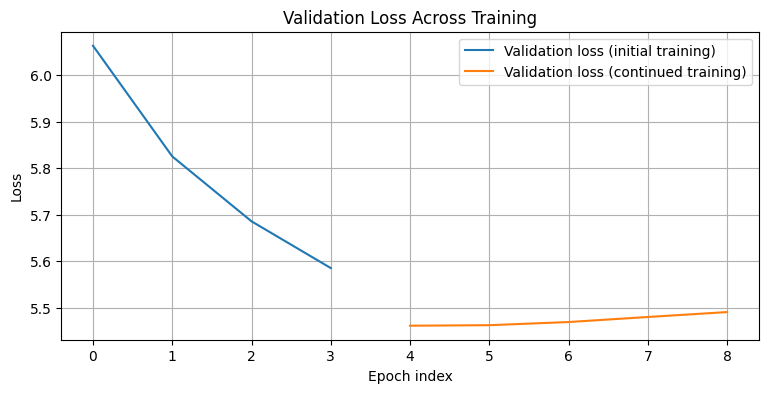

In [35]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))

plt.plot(
    history.history["val_loss"],
    label="Validation loss (initial training)"
)

# history_more contains the additional training epochs
plt.plot(
    range(
        len(history.history["val_loss"]),
        len(history.history["val_loss"]) + len(history_more.history["val_loss"])
    ),
    history_more.history["val_loss"],
    label="Validation loss (continued training)"
)

plt.xlabel("Epoch index")
plt.ylabel("Loss")
plt.title("Validation Loss Across Training")
plt.legend()
plt.grid(True)
plt.show()


In [36]:

model.save("/content/next_word_lstm_improved.keras")

with open(
    "/content/next_word_tokenizer.json",
    "w",
    encoding="utf-8"
) as f:
    f.write(tokenizer.to_json())

print("Improved model and tokenizer saved.")


Improved model and tokenizer saved.


In [38]:

from google.colab import files

model.save("/content/next_word_lstm_improved.keras")

with open("/content/next_word_tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())

files.download("/content/next_word_lstm_improved.keras")
files.download("/content/next_word_tokenizer.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>